# Librerias y constantes

In [8]:
import numpy as np
from scipy.special import zeta
from scipy.integrate import cumulative_trapezoid, solve_ivp

import matplotlib.pyplot as plt

OB = .05
OM = .27

ETA_B = 2.74E-8 * OB
ME = .5 #MeV
T0 = 2.35E-10 #MeV
ALPHA = 1/137
HBAR = 6.5822E-22 #MeV*s
C = 2E8 #m/s
B = 13.6 / 1E6 #MeV
H0 = 1.5E-39 #MeV

TR = 3E-7 #MeV

SIGMAT = 8*np.pi/3 * (ALPHA / ME)**2 #MeV-2

# Item $(a)$

Calculo el camino libre medio de un fotón.

In [9]:
CLM = lambda T: np.pi**2 / (ETA_B * SIGMAT * 2 * zeta(3)) / T**3
print('El CLM de un foton = ', CLM(T0)*(HBAR*C), 'm')

El CLM de un foton =  1.7024884598319858e+28 m


# Item $(b)$

Para la segunda aproximación necesito utilizar el $X_+$ que conseguí en el **P1**

In [10]:
def X_p(T):
    a = 3.84 * ETA_B * (T/ME)**(3/2) * np.exp(B/T)
    return (-1 + np.sqrt(1 + (4*a))) / (2 * a)

X_res = 2E-4 * np.sqrt(OM / .14) * (.022 / OB)

CLM_X = lambda T, X: np.pi**2 / (ETA_B * SIGMAT * 2 * zeta(3)) / (X * T**3)

print('El CLM previo a recombinación:', CLM_X(TR, X_p(TR))*(HBAR * C))
print('El CLM posterior a recombinación:', CLM_X(TR, X_res)*(HBAR * C))

El CLM previo a recombinación: 9.3530522220794e+19
El CLM posterior a recombinación: 6.696123624291601e+22


# Item $(c)$

Sin importar cual sea el modelo de ionización, la *profundidad óptica* la voy a obtener integrando numéricamente la siguiente expresión:

$$\tau (T_, T_0) = \sigma_T \eta_b \frac{\zeta(3) T_0^{9/2}}{\pi^2 H_0 \sqrt{\Omega_{b,0}}} \int_{T_0}^{T_e} \frac{dT}{T^{5/2}}X(T)$$

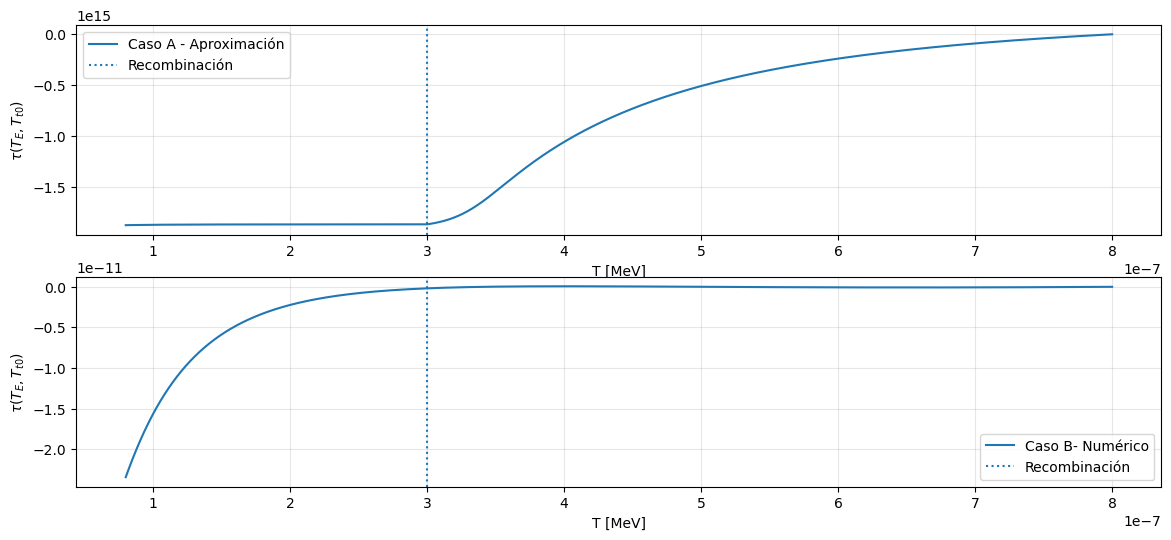

In [31]:
def X_1(T):
    if T > TR:
        return X_p(T)
    else:
        return X_res

def dXdx(T, X):
    thermal = 9.78 * ALPHA**2 / ME**2 * np.sqrt(B/T) * np.log(B/T)
    
    f_factor = (ME * T / 2 / np.pi)**(3/2) * np.exp(-B/T) * (1 - X)
    s_factor = ETA_B * 2 * zeta(3) / np.pi**2 * T**3 * X**2
    return thermal * (f_factor - s_factor)



# Condición inicial y límites
T_E, T_0 = .8E-7, .8E-6 #MeV
X0 = X_p(T_E)

sol = solve_ivp(dXdx, [T_E, T_0], [X0], method='Radau', rtol=1e-8, atol=1e-12, dense_output=True)

def prof(X, Ts):
    Xv = np.array([X(T) for T in Ts])
    integrando = Xv * Ts**(-5/2)
    return SIGMAT * ETA_B * zeta(3) * T_0**(9/2) / (np.pi**2 * H0 * np.sqrt(OB)) * cumulative_trapezoid(integrando, np.log(Ts), initial=0)

Ts = np.geomspace(T_0, T_E, 50_000)

X_ode = lambda T: sol.sol(T)[0]

tau_ode = prof(X_ode, Ts)
tau_X1  = prof(X_1, Ts)

fig, axs = plt.subplots(2, 1, figsize = (14, 6))

axs[0].plot(Ts, tau_X1, label = 'Caso A - Aproximación')
axs[1].plot(Ts, tau_ode, label = 'Caso B- Numérico')

axs[0].axvline(TR, linestyle = ':', label = 'Recombinación')
axs[1].axvline(TR, linestyle = ':', label = 'Recombinación')

axs[0].set(xlabel = 'T [MeV]', ylabel = r'$\tau(T_E, T_{t0})$')
axs[1].set(xlabel = 'T [MeV]', ylabel = r'$\tau(T_E, T_{t0})$')
axs[0].grid(alpha = .3), axs[0].legend()
axs[1].grid(alpha = .3), axs[1].legend()

fig.savefig('Profundidad_optica.png', bbox_inches = 'tight')

# Item $(d)$

In [32]:
Tx = ( ( ( (3*np.pi**2*H0*np.sqrt(OB)) / (2 * T0**(9/2)) ) - (TR**(3/2) - T0**(3/2)) ) / X_res )**(2/3)
Tx

910697.6852207549